# Recompute B (Tyrlis & Hoskins 2008)

At each longitude: mean theta in a 15° lat × 5° lon box north of the central latitude minus the box south of it; B is the max over central latitudes CBL − 4°, CBL, CBL + 4°.

## Data source

ERA-40 files on the 2 PVU surface (`e4oper.an.pv.YYYYMM`, Sept 1957 – Aug 2002); only theta (`pt`) is read.

In [1]:
import glob

theta_files = sorted(glob.glob("../data/e4oper.an.pv.*"))
print(len(theta_files), "files:", theta_files[0], "to", theta_files[-1])

540 files: ../data/e4oper.an.pv.195709 to ../data/e4oper.an.pv.200208


## Setup

In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")
from plot_era40 import _valid_time, _reduced_to_full   # importing plot_era40 also sets up eccodes in the right order
import eccodes as ec
from blocking_index import band_weights   # Matthew's latitude-interpolated band means

Reads every 6-hourly theta field in one monthly file in a single pass.

In [ ]:
def read_theta_month(path):
    """Return lats, lons, times, theta with shape (time, lat, lon)."""
    lats = lons = None
    times, fields = [], []
    with open(path, "rb") as f:
        while (gid := ec.codes_grib_new_from_file(f)) is not None:
            try:
                if ec.codes_get(gid, "shortName") != "pt":
                    continue
                if ec.codes_get(gid, "gridType") == "reduced_gg":
                    arr = _reduced_to_full(ec.codes_get_values(gid), ec.codes_get_array(gid, "pl").astype(int))
                else:
                    arr = ec.codes_get_values(gid).reshape(ec.codes_get(gid, "Nj"), ec.codes_get(gid, "Ni"))
                if lats is None:
                    lats = ec.codes_get_array(gid, "distinctLatitudes")
                    lons = np.arange(arr.shape[1]) * 360.0 / arr.shape[1]
                times.append(_valid_time(gid))
                fields.append(arr)
            finally:
                ec.codes_release(gid)
    order = np.argsort(times)
    return lats, lons, [times[i] for i in order], np.array(fields)[order]

## Central latitude (paper's Fig. 1, black curve) and B

In [ ]:
TARGET_LONS = np.arange(0, 360, 5)
SHIFTS = [-4, 0, 4]   # central latitude CBL - 4, CBL, CBL + 4

CBL_TH08 = np.array([
    56.5, 56.6, 57.1, 57.8, 58.2, 58.8, 58.9, 59.1, 60.0, 60.0, 60.0, 60.0,
    60.0, 59.6, 59.0, 58.9, 58.9, 58.9, 58.8, 57.8, 57.2, 55.3, 52.4, 49.1,
    46.8, 45.2, 44.4, 44.3, 44.3, 44.3, 44.4, 44.7, 45.4, 45.4, 45.4, 45.4,
    45.4, 45.5, 45.5, 45.6, 46.1, 46.4, 46.6, 47.4, 47.6, 47.6, 47.7, 47.8,
    48.5, 48.8, 48.8, 48.7, 47.8, 47.7, 46.8, 46.7, 47.4, 47.6, 47.8, 48.1,
    48.8, 49.7, 50.5, 51.3, 52.1, 52.8, 53.4, 54.2, 54.4, 55.2, 55.5, 55.5])

`W @ theta` gives north-band mean minus south-band mean for every (shift, longitude) at once. Each 15° band is averaged with linear interpolation in latitude (`band_weights`), then over the 5° longitude box.

In [ ]:
def lon_box(lons, lon_c, half_width=2.5):
    """Equal weights over the grid longitudes within 2.5° of lon_c."""
    in_lon = np.abs((lons - lon_c + 180) % 360 - 180) <= half_width
    return in_lon / in_lon.sum()

def build_B_weights(lats, lons):
    W = np.zeros((len(SHIFTS), len(TARGET_LONS), lats.size * lons.size))
    for s, shift in enumerate(SHIFTS):
        for j, (lon, c0) in enumerate(zip(TARGET_LONS, CBL_TH08)):
            c = c0 + shift
            lat_w = band_weights(lats, c, c + 15) - band_weights(lats, c - 15, c)
            W[s, j] = np.outer(lat_w, lon_box(lons, lon)).ravel()
    return W

def compute_B(theta, W):
    """theta (time, lat, lon) -> B (time, longitude): max over the three central latitudes."""
    flat = theta.reshape(len(theta), -1)
    B_all = (W.reshape(-1, flat.shape[1]) @ flat.T).reshape(len(SHIFTS), len(TARGET_LONS), -1)
    return B_all.max(axis=0).T

## Compute B for every file

B at each 6-hourly time, then the daily mean (as in the paper). Saved to `results/ERA40_B_index_daily_1957-2002_TH08.parquet`; if that file exists, it is loaded instead of recomputed (delete it to recompute).

In [6]:
import os

B_FILE = "../results/ERA40_B_index_daily_1957-2002_TH08.parquet"

if os.path.exists(B_FILE):
    B_daily = pd.read_parquet(B_FILE).rename(columns=int)
else:
    W = None
    daily_B = []
    for path in theta_files:
        lats, lons, times, theta = read_theta_month(path)
        if W is None:
            W = build_B_weights(lats, lons)
        B = pd.DataFrame(compute_B(theta, W), index=pd.DatetimeIndex(times), columns=TARGET_LONS)
        daily_B.append(B.resample("D").mean())
        print(path, "done")
    B_daily = pd.concat(daily_B).sort_index()   # rows = days, columns = longitude
    os.makedirs("../results", exist_ok=True)
    B_daily.rename(columns=str).to_parquet(B_FILE)   # parquet needs text column names

../data/e4oper.an.pv.195709 done


../data/e4oper.an.pv.195710 done


../data/e4oper.an.pv.195711 done


../data/e4oper.an.pv.195712 done


../data/e4oper.an.pv.195801 done


...

../data/e4oper.an.pv.200204 done


../data/e4oper.an.pv.200205 done


../data/e4oper.an.pv.200206 done


../data/e4oper.an.pv.200207 done


../data/e4oper.an.pv.200208 done


## Check against the paper's Fig. 4b

Winter (DJF) mean, standard deviation and skewness of B at each longitude.

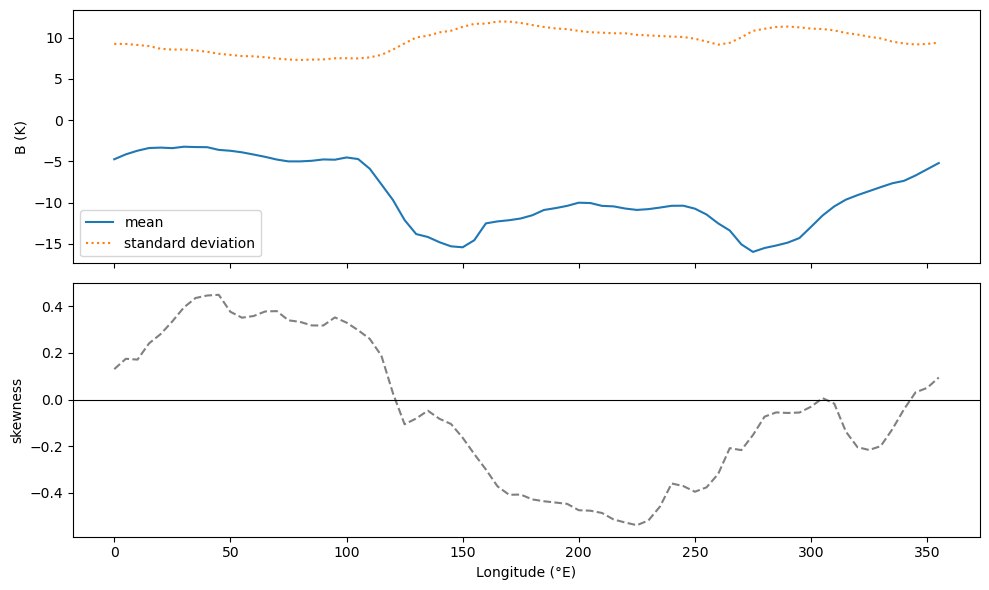

In [7]:
djf = B_daily[B_daily.index.month.isin([12, 1, 2])]

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(TARGET_LONS, djf.mean(), label="mean")
axes[0].plot(TARGET_LONS, djf.std(), ":", label="standard deviation")
axes[0].set_ylabel("B (K)")
axes[0].legend()
axes[1].plot(TARGET_LONS, djf.skew(), "--", color="gray")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("skewness")
axes[1].set_xlabel("Longitude (°E)")
plt.tight_layout()
plt.show()